# Compare linear regression models with regularisation: Ridge, Lasso, OLS

In [1]:
# import libraries

import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, cross_validate, train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

from statsmodels.stats.outliers_influence import variance_inflation_factor
import scipy.stats as stats
import statsmodels.api as sm


## Load data and feature selection

In [2]:
# Loading the dataset

df = pd.read_csv("~/Documents/PlayTime/LMD_Modelling/data/processed/processed_data.csv")


target = "porosity_%" # change to other targets as needed

# use core process parameters  as inputs (avoid LED/VED to reduce multicolinearity)
features = ["Power","Speed", "Feed"] 

X = df[features].copy()
y = df[target].copy()

print("Features shape: ", X.shape)
print("Target shape", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Features shape:  (89, 3)
Target shape (89,)


In [3]:
# define models with regularization techniques
models = {
    "OLS": LinearRegression(),
    "Ridge": Ridge(alpha=10),    # Try alpha values like 0.1, 1.0, 10.0
    "Lasso": Lasso(alpha=0.01)      # Try alpha values like 0.01, 0.1, 1.0
}

Note on alpha:

Ridge/Lasso α controls regularization strength (higher α → more shrinkage).

Start with α=1.0 for Ridge, α=0.01 for Lasso; tune later if needed.

In [4]:
# Fit models and evaluate
results = {}

for name, model in models.items():
    # Fit
    model.fit(X_train_scaled, y_train)
    
    # Predictions
    y_train_pred = model.predict(X_train_scaled)
    y_test_pred = model.predict(X_test_scaled)
    
    # Metrics
    results[name] = {
        "R2_train": r2_score(y_train, y_train_pred),
        "R2_test": r2_score(y_test, y_test_pred),
        "RMSE_train": np.sqrt(mean_squared_error(y_train, y_train_pred)),
        "RMSE_test": np.sqrt(mean_squared_error(y_test, y_test_pred)),
        "MAE_train": mean_absolute_error(y_train, y_train_pred),
        "MAE_test": mean_absolute_error(y_test, y_test_pred),
        "MSE_train": mean_squared_error(y_train, y_train_pred),
        "MSE_test": mean_squared_error(y_test, y_test_pred)
    }

# Convert to DataFrame for easy viewing
results_df = pd.DataFrame(results).T
print(results_df)


       R2_train   R2_test  RMSE_train  RMSE_test  MAE_train  MAE_test  \
OLS    0.434414 -4.809382    0.377224   0.345668   0.227305  0.295381   
Ridge  0.429376 -4.199876    0.378900   0.327032   0.217930  0.285930   
Lasso  0.433383 -4.541813    0.377567   0.337613   0.223254  0.290315   

       MSE_train  MSE_test  
OLS     0.142298  0.119486  
Ridge   0.143565  0.106950  
Lasso   0.142557  0.113983  


In [5]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = {}

for name, model in models.items():
    # Fit scaler + model in a pipeline for proper CV
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("model", model)
    ])
    
    # Cross-validate
    scores = cross_validate(
        pipe, X, y, cv=cv,
        scoring={
            "r2": "r2",
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "mse": "neg_mean_squared_error"
        },
        return_train_score=False
    )
    
    cv_results[name] = {
        "R2_CV_mean": scores["test_r2"].mean(),
        "R2_CV_std": scores["test_r2"].std(),
        "RMSE_CV_mean": -scores["test_rmse"].mean(),
        "RMSE_CV_std": scores["test_rmse"].std(),
        "MAE_CV_mean": -scores["test_mae"].mean(),
        "MAE_CV_std": scores["test_mae"].std(),
        "MSE_CV_mean": -scores["test_mse"].mean(),
        "MSE_CV_std": scores["test_mse"].std()
    }

cv_results_df = pd.DataFrame(cv_results).T
print("\n--- Cross-Validation Results ---")
print(cv_results_df)



--- Cross-Validation Results ---
       R2_CV_mean  R2_CV_std  RMSE_CV_mean  RMSE_CV_std  MAE_CV_mean  \
OLS     -0.640766   2.091335      0.362698     0.155305     0.242006   
Ridge   -0.516252   1.849556      0.359960     0.160160     0.231920   
Lasso   -0.590832   1.983432      0.362462     0.157524     0.237515   

       MAE_CV_std  MSE_CV_mean  MSE_CV_std  
OLS      0.056547     0.155670    0.140023  
Ridge    0.057223     0.155223    0.145527  
Lasso    0.056587     0.156192    0.142638  


In [7]:
# Automatic hyperparameter tuning

# RidgeCV: tries multiple alphas automatically
ridge_cv = RidgeCV(alphas=[0.001, 0.01, 0.1, 1.0, 10.0, 100.0], cv=5)
ridge_cv.fit(X_train_scaled, y_train)
print(f"Best Ridge alpha: {ridge_cv.alpha_}")

# LassoCV: tries multiple alphas automatically
lasso_cv = LassoCV(alphas=[0.0001, 0.001, 0.01, 0.1, 1.0], cv=5, random_state=42)
lasso_cv.fit(X_train_scaled, y_train)
print(f"Best Lasso alpha: {lasso_cv.alpha_}")

# Update models with best alphas
models["Ridge_tuned"] = Ridge(alpha=ridge_cv.alpha_)
models["Lasso_tuned"] = Lasso(alpha=lasso_cv.alpha_)

# Re-run metrics with tuned models (repeat Cell 4 or Cell 5)


Best Ridge alpha: 10.0
Best Lasso alpha: 0.01


  Feature       OLS     Ridge     Lasso
0   Power -0.119660 -0.107888 -0.110700
1   Speed -0.220476 -0.196690 -0.212874
2    Feed  0.175098  0.155486  0.165739


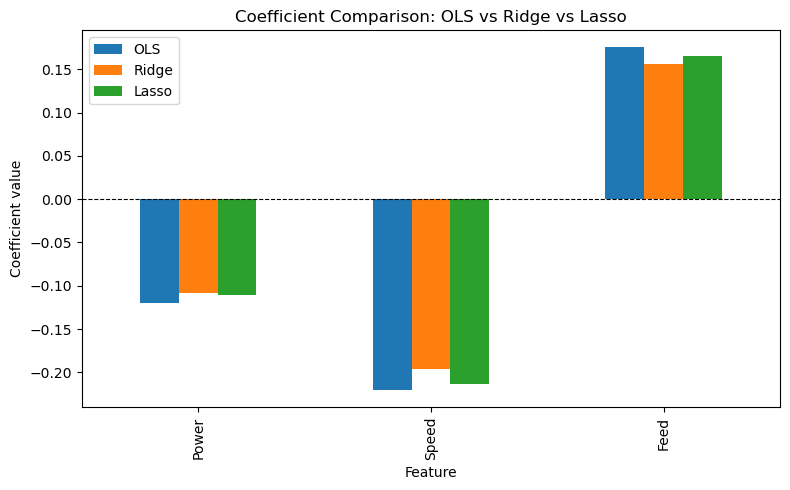

In [8]:
# Visualize Coefficients

# Extract coefficients
coef_comparison = pd.DataFrame({
    "Feature": X.columns,
    "OLS": models["OLS"].coef_,
    "Ridge": models["Ridge"].coef_,
    "Lasso": models["Lasso"].coef_
})

print(coef_comparison)

# Plot
coef_comparison.set_index("Feature").plot(kind="bar", figsize=(8, 5))
plt.ylabel("Coefficient value")
plt.title("Coefficient Comparison: OLS vs Ridge vs Lasso")
plt.axhline(0, color="black", linestyle="--", linewidth=0.8)
plt.legend()
plt.tight_layout()
plt.show()


In [9]:
# Summary table 

summary = pd.DataFrame({
    "Model": ["OLS", "Ridge", "Lasso"],
    "R²_train": [results["OLS"]["R2_train"], results["Ridge"]["R2_train"], results["Lasso"]["R2_train"]],
    "R²_test": [results["OLS"]["R2_test"], results["Ridge"]["R2_test"], results["Lasso"]["R2_test"]],
    "RMSE_CV": [cv_results["OLS"]["RMSE_CV_mean"], cv_results["Ridge"]["RMSE_CV_mean"], cv_results["Lasso"]["RMSE_CV_mean"]],
    "MAE_CV": [cv_results["OLS"]["MAE_CV_mean"], cv_results["Ridge"]["MAE_CV_mean"], cv_results["Lasso"]["MAE_CV_mean"]]
})

print(summary.to_string(index=False))


Model  R²_train   R²_test  RMSE_CV   MAE_CV
  OLS  0.434414 -4.809382 0.362698 0.242006
Ridge  0.429376 -4.199876 0.359960 0.231920
Lasso  0.433383 -4.541813 0.362462 0.237515
